In [1]:
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import glob

In [2]:
def fastq_to_dataframe(fastq_path):
    records = []
    with open(fastq_path) as f:
        while True:
            header = f.readline().strip()
            if not header:
                break
            seq = f.readline().strip()
            plus = f.readline().strip()
            qual = f.readline().strip()
            records.append({
                "header": header,
                "Sequence": seq,

            })
    return pd.DataFrame(records)


def reverse_complement(seq):
    comp = str.maketrans("ACGTacgt", "TGCAtgca")
    return seq.translate(comp)[::-1]


def analyze_sgrnas(path, file_format="fastq"):
    print(path)
    if file_format=="fastq":
        df = fastq_to_dataframe(path)
        
        total_rows = sum(1 for _ in open(path))
        
        motif_1 = re.compile("CACCGGGTCTTCGAGAAGACCTGTTT", re.IGNORECASE)
        motif_2 = re.compile("AAACAGGTCTTCTCGAAGACCCGGTG", re.IGNORECASE)

        undigested_1 = df["Sequence"].str.contains(motif_1).sum()
        undigested_2 = df["Sequence"].str.contains(motif_2).sum()
        
        percent_undigested = round(
            100 * (undigested_1 + undigested_2) / (total_rows / 3),
            3
        )
        
        print(f"{percent_undigested}% undigested plasmid")
        
        pattern_fwd = re.compile(r"(?<=cgaaacacc).*?(?=gtttaagag)", re.IGNORECASE)
        pattern_rev = re.compile(r"(?<=ctcttaaac).*?(?=ggtgtttcg)", re.IGNORECASE)
        
        lib = path
        
    elif file_format=="csv":
        df = pd.read_csv(path)
        
        pattern_fwd = re.compile(r"(?<=GGAAGACGGCACC).*?(?=GTTTGGGTCTTCGC)", re.IGNORECASE)
        pattern_rev = re.compile(r"(?<=GGAAGACGGCACC).*?(?=GGAAGACGGCACC)", re.IGNORECASE)

        lib = df["Pool name"]
        
    else:
        raise ValueError("Must be fastq or csv")
        
    sgrnas = []

    for seq in df["Sequence"]:
        # forward
        for m in pattern_fwd.findall(seq):
            if 19 < len(m) < 22:
                sgrnas.append(m)

        # reverse
        for m in pattern_rev.findall(seq):
            if 19 < len(m) < 22:
                sgrnas.append(reverse_complement(m))

    sgrna_df = pd.DataFrame({
        "id": range(1, len(sgrnas) + 1),
        "Sequence": sgrnas,
        "lib": lib,
    })

    return sgrna_df

In [3]:
csvs = glob.glob("*csv")
#fastq file is Plasmidsaurus output
fastqs = glob.glob("*.fastq")

In [4]:
df1 = pd.concat([analyze_sgrnas(file, file_format="fastq") for file in fastqs])
df1["lib"] = df1["lib"].apply(lambda x: x.split("_")[0])
df2 = pd.concat([analyze_sgrnas(file, file_format="csv") for file in csvs])

pShhx100_seq.fastq
0.0% undigested plasmid
pShhx100.csv


In [5]:
counts = (
    df1
    .groupby(["Sequence", "lib"])
    .size()
    .reset_index(name="count")
)

file_totals = (
    df1
    .groupby(["lib"])
    .size()
    .reset_index(name="lib_total")
)

df3 = df2.merge(
    counts,
    on=["Sequence"],
    how="left"
).merge(
    file_totals, 
    left_on="lib_x",
    right_on="lib", 
    how="left"
)

df3["count"] = df3["count"].fillna(0).astype(int)
df3["percent_count"] = (df3["count"] / df3["lib_total"]) * 100
df3 = df3[df3["lib_x"].isin(df1.lib.unique())]

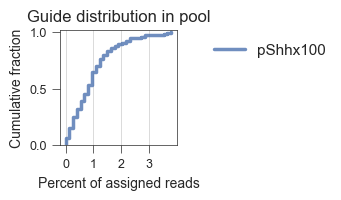

In [6]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5, 1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

g = sns.ecdfplot(data=df3, x="percent_count", 
                 linewidth=2.5, hue="lib_x", alpha=0.8, legend=True,
                 )
g.set(ylim=[0, 1.02], title="Guide distribution in pool")
sns.move_legend(obj=g, loc="upper right", bbox_to_anchor=(2.4,1), frameon=False, title="")
plt.yticks([0, 0.5, 1])
plt.xticks([0, 1, 2, 3])
g.set_xlabel("Percent of assigned reads", fontsize=10)
g.set_ylabel("Cumulative fraction", fontsize=10)
g.tick_params(axis='both', labelsize=9)
g.grid(True, axis="x", linewidth=0.5)